# 11 FDI Structural-Ties Scoring Development

## Purpose

Notebook 10 established the production source and reporting perspective. This notebook evaluates scoring formulations for the FDI structural-ties component.

The object is the **anchor's outward direct-investment position in each country**. The development window is **2018–2024**, because China's official anchor-to-country series is absent before 2018 and stable thereafter.

The notebook compares three 0–1 formulations and selects a transparent production candidate without yet moving logic into `src/`.

## Decisions carried forward from Notebook 10

- Use IMF DIP official asset-owner reporting only.
- Use `anchor_to_country` positions only.
- Preserve missing values as missing.
- Preserve observed zero and negative positions in the audit fields.
- For a non-negative closeness score, zero and negative net positions receive zero intensity rather than being converted to absolute values.
- Exclude aggregates, out-of-master territories, historical entities outside their valid period, and anchor self-relations.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)


def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").exists() and (candidate / "notebooks").exists():
            return candidate
    raise FileNotFoundError("Run this notebook from inside the project repository.")


PROJECT_ROOT = find_project_root()
IMF_PATH = PROJECT_ROOT / "data" / "interim" / "fdi" / "imf_dip_primary_candidates.csv"
CROSSWALK_PATH = PROJECT_ROOT / "outputs" / "tables" / "fdi" / "imf_dip_country_crosswalk_audit.csv"
COUNTRY_MASTER_PATH = PROJECT_ROOT / "outputs" / "tables" / "relations_condition" / "relationship_condition_country_master.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "tables" / "fdi"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required_paths = [IMF_PATH, CROSSWALK_PATH, COUNTRY_MASTER_PATH]
missing = [p.relative_to(PROJECT_ROOT) for p in required_paths if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing required repository inputs: {missing}")

print("Project root: .")
for path in required_paths:
    print(path.relative_to(PROJECT_ROOT))
print(f"Output directory: {OUTPUT_DIR.relative_to(PROJECT_ROOT)}")

Project root: .
data/interim/fdi/imf_dip_primary_candidates.csv
outputs/tables/fdi/imf_dip_country_crosswalk_audit.csv
outputs/tables/relations_condition/relationship_condition_country_master.csv
Output directory: outputs/tables/fdi


## 1. Load the established production inputs

In [2]:
imf = pd.read_csv(IMF_PATH)
crosswalk = pd.read_csv(CROSSWALK_PATH)
country_master = pd.read_csv(COUNTRY_MASTER_PATH)

required_imf = {"country_source_name", "anchor", "reporting_perspective", "economic_direction", "DV_TYPE", "year", "fdi_position_usd_millions"}
required_crosswalk = {"country_source_name", "country_iso3", "country_name", "dip_period_eligible"}
assert required_imf.issubset(imf.columns)
assert required_crosswalk.issubset(crosswalk.columns)
assert crosswalk["country_source_name"].is_unique

print(f"IMF candidate rows: {len(imf):,}")
print(f"Mapped IMF names: {crosswalk['country_iso3'].notna().sum():,}")

IMF candidate rows: 48,192
Mapped IMF names: 170


## 2. Select official outward positions and construct the full 2018–2024 grid

In [3]:
ANCHOR_ISO3 = {"China": "CHN", "United States": "USA"}
START_YEAR, END_YEAR = 2018, 2024

mapped = imf.merge(
    crosswalk[["country_source_name", "country_iso3", "country_name", "dip_period_eligible"]],
    on="country_source_name", how="left", validate="many_to_one"
)

selected = mapped.loc[
    mapped["country_iso3"].notna()
    & mapped["dip_period_eligible"].astype("boolean").fillna(False)
    & mapped["economic_direction"].eq("anchor_to_country")
    & mapped["reporting_perspective"].eq("anchor_report")
    & mapped["DV_TYPE"].eq("Reported official data")
    & mapped["year"].between(START_YEAR, END_YEAR)
].copy()
selected = selected.loc[
    selected["country_iso3"] != selected["anchor"].map(ANCHOR_ISO3)
]

KEYS = ["country_iso3", "anchor", "year"]
assert not selected.duplicated(KEYS).any()

eligible = country_master.loc[
    ~country_master["iso3"].isin({"BYS","CSK","DDR","DHY","HVO","RHO","SCG","SVU","VDR","YUG"}),
    ["iso3", "country_name"]
].rename(columns={"iso3":"country_iso3"})

grid = pd.MultiIndex.from_product(
    [eligible["country_iso3"], ["China", "United States"], range(START_YEAR, END_YEAR + 1)],
    names=KEYS,
).to_frame(index=False)
grid = grid.loc[
    grid["country_iso3"] != grid["anchor"].map(ANCHOR_ISO3)
].merge(eligible, on="country_iso3", how="left", validate="many_to_one")

panel = grid.merge(
    selected[KEYS + ["fdi_position_usd_millions"]],
    on=KEYS, how="left", validate="one_to_one"
).rename(columns={"fdi_position_usd_millions":"fdi_outward_position_usd_mn"})

panel["observed"] = panel["fdi_outward_position_usd_mn"].notna()
panel["observed_zero"] = panel["fdi_outward_position_usd_mn"].eq(0)
panel["observed_negative"] = panel["fdi_outward_position_usd_mn"].lt(0)
panel["positive_position_usd_mn"] = panel["fdi_outward_position_usd_mn"].clip(lower=0)

panel.groupby(["year","anchor"], as_index=False).agg(
    eligible=("country_iso3","size"), observed=("observed","sum"),
    zeros=("observed_zero","sum"), negatives=("observed_negative","sum")
)

,year,anchor,eligible,observed,zeros,negatives
0,2018,China,202,168,15,0
1,2018,United States,202,146,22,5
2,2019,China,202,168,16,0
3,2019,United States,202,142,21,10
4,2020,China,202,168,14,0
5,2020,United States,202,143,21,9
6,2021,China,202,168,13,0
7,2021,United States,202,143,21,10
8,2022,China,202,168,13,0
9,2022,United States,202,139,19,3


## 3. Candidate score formulations

All candidates preserve missingness.

1. **Portfolio share**: positive position divided by the anchor's annual total positive outward position. Strong economic interpretation, but values are highly concentrated and generally small.
2. **Positive-position percentile**: percentile rank among observed positive positions. Robust but discards magnitude.
3. **Winsorised log intensity**: `log1p(positive position)` divided by the anchor-year 95th percentile of positive log positions, capped at 1. This preserves magnitude ordering while limiting domination by a few financial centres.

Observed zero and negative positions receive zero under all three non-negative methods.

In [4]:
def add_scores(group: pd.DataFrame) -> pd.DataFrame:
    group = group.copy()
    observed = group["observed"]
    positive = group["positive_position_usd_mn"]

    total_positive = positive[observed].sum()
    group["score_portfolio_share"] = np.where(
        observed,
        positive / total_positive if total_positive > 0 else 0.0,
        np.nan,
    )

    positive_mask = observed & positive.gt(0)
    percentile = pd.Series(0.0, index=group.index)
    percentile.loc[positive_mask] = positive.loc[positive_mask].rank(method="average", pct=True)
    percentile.loc[~observed] = np.nan
    group["score_positive_percentile"] = percentile

    log_positive = np.log1p(positive)
    cap = log_positive.loc[positive_mask].quantile(0.95)
    group["score_log_p95"] = np.where(
        observed,
        np.minimum(log_positive / cap, 1.0) if cap > 0 else 0.0,
        np.nan,
    )
    group["log_p95_cap"] = cap
    return group


scored = pd.concat(
    [add_scores(group) for _, group in panel.groupby(["anchor", "year"], sort=True)],
    ignore_index=True,
)

score_columns = ["score_portfolio_share", "score_positive_percentile", "score_log_p95"]
assert scored.loc[~scored["observed"], score_columns].isna().all().all()
assert scored.loc[scored["observed_negative"], score_columns].eq(0).all().all()
assert scored[score_columns].min().min() >= 0
assert scored[score_columns].max().max() <= 1
scored[score_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
score_portfolio_share,2171.0,0.006449,0.047336,0.0,0.000007,0.000158,0.001187,0.80096
score_positive_percentile,2171.0,0.435744,0.318986,0.0,0.136558,0.425806,0.714901,1.00000
score_log_p95,2171.0,0.520802,0.312367,0.0,0.281038,0.577809,0.762996,1.00000


## 4. Sensitivity across methods

In [5]:
sensitivity_rows = []
for (anchor, year), group in scored.groupby(["anchor","year"]):
    observed = group.dropna(subset=score_columns)
    sensitivity_rows.append({
        "anchor": anchor,
        "year": year,
        "observed_countries": len(observed),
        "portfolio_vs_percentile_spearman": observed["score_portfolio_share"].corr(observed["score_positive_percentile"], method="spearman"),
        "portfolio_vs_log_p95_spearman": observed["score_portfolio_share"].corr(observed["score_log_p95"], method="spearman"),
        "percentile_vs_log_p95_spearman": observed["score_positive_percentile"].corr(observed["score_log_p95"], method="spearman"),
        "portfolio_top5_share": observed["score_portfolio_share"].nlargest(5).sum(),
        "log_p95_capped_countries": observed["score_log_p95"].eq(1).sum(),
    })
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity

,anchor,year,observed_countries,portfolio_vs_percentile_spearman,portfolio_vs_log_p95_spearman,percentile_vs_log_p95_spearman,portfolio_top5_share,log_p95_capped_countries
0,China,2018,168,1.0,0.999947,0.999947,0.856126,8
1,China,2019,168,1.0,0.999947,0.999947,0.869447,8
2,China,2020,168,1.0,0.999947,0.999947,0.851727,8
3,China,2021,168,1.0,0.999947,0.999947,0.853943,8
4,China,2022,168,1.0,0.999947,0.999947,0.853425,8
5,China,2023,168,1.0,0.999947,0.999947,0.863213,8
6,China,2024,168,1.0,0.999947,0.999947,0.866674,8
7,United States,2018,146,1.0,0.999966,0.999966,0.621218,6
8,United States,2019,142,1.0,0.999963,0.999963,0.611652,6
9,United States,2020,143,1.0,0.999964,0.999964,0.605053,6


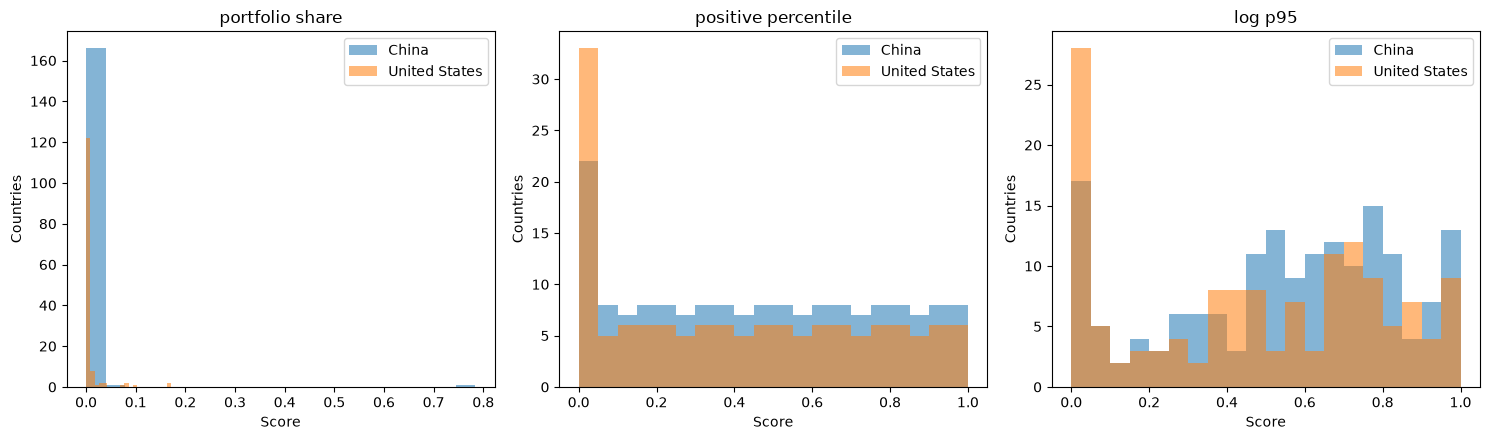

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
latest = scored.loc[scored["year"].eq(END_YEAR)]
for ax, column in zip(axes, score_columns):
    for anchor, group in latest.groupby("anchor"):
        ax.hist(group[column].dropna(), bins=20, alpha=0.55, label=anchor)
    ax.set_title(column.replace("score_", "").replace("_", " "))
    ax.set_xlabel("Score")
    ax.set_ylabel("Countries")
    ax.legend()
plt.tight_layout()
plt.show()

## 5. US–China comparison under each candidate

The comparison is formed only when both anchor scores are observed for the same country-year. Positive values indicate greater US outward-FDI intensity; negative values indicate greater Chinese outward-FDI intensity.

In [7]:
comparison_parts = []
for method in score_columns:
    wide = scored.pivot(index=["country_iso3","country_name","year"], columns="anchor", values=method).reset_index()
    wide["method"] = method
    wide["us_minus_china"] = wide.get("United States") - wide.get("China")
    comparison_parts.append(wide)
comparison = pd.concat(comparison_parts, ignore_index=True)

comparison_coverage = (
    comparison.groupby(["method","year"], as_index=False)
    .agg(
        countries=("country_iso3","size"),
        both_anchors_observed=("us_minus_china","count"),
    )
)
comparison_coverage["both_anchors_observed_pct"] = 100 * comparison_coverage["both_anchors_observed"] / comparison_coverage["countries"]
comparison_coverage

,method,year,countries,both_anchors_observed,both_anchors_observed_pct
0,score_log_p95,2018,203,146,71.921182
1,score_log_p95,2019,203,142,69.950739
2,score_log_p95,2020,203,143,70.443350
3,score_log_p95,2021,203,143,70.443350
4,score_log_p95,2022,203,139,68.472906
5,score_log_p95,2023,203,141,69.458128
6,score_log_p95,2024,203,141,69.458128
7,score_portfolio_share,2018,203,146,71.921182
8,score_portfolio_share,2019,203,142,69.950739
9,score_portfolio_share,2020,203,143,70.443350


## 6. Production recommendation

**Recommended candidate: winsorised log intensity (`score_log_p95`).**

Rationale:

- keeps the economically meaningful magnitude ordering of outward positions;
- compresses the extreme right tail without replacing values by ranks;
- produces a bounded 0–1 anchor-specific score suitable for later component aggregation;
- treats negative and zero net positions as zero current closeness intensity while retaining their original values and flags;
- leaves missing positions missing;
- uses only contemporaneous anchor-year information;
- is transparent and reproducible.

The common production period is **2018–2024**. Earlier years are unavailable for China's official outward positions and must not be backfilled with zeros.

## 7. Export the production candidate and diagnostics

The output is still labelled a candidate because final component weighting and integration with the complete index occur downstream.

In [8]:
production_candidate = scored[[
    "country_iso3", "country_name", "anchor", "year",
    "fdi_outward_position_usd_mn", "observed", "observed_zero", "observed_negative",
    "score_log_p95", "log_p95_cap",
]].rename(columns={"score_log_p95":"fdi_structural_score_raw"})
production_candidate["method"] = "official_outward_positive_log1p_scaled_to_anchor_year_p95"
production_candidate["source"] = "IMF Direct Investment Positions"

exports = {
    "fdi_structural_score_candidate.csv": production_candidate,
    "fdi_scoring_method_sensitivity.csv": sensitivity,
    "fdi_scoring_comparison_coverage.csv": comparison_coverage,
}
for filename, frame in exports.items():
    path = OUTPUT_DIR / filename
    frame.to_csv(path, index=False)
    print(f"Wrote {path.relative_to(PROJECT_ROOT)} ({len(frame):,} rows)")

Wrote outputs/tables/fdi/fdi_structural_score_candidate.csv (2,828 rows)
Wrote outputs/tables/fdi/fdi_scoring_method_sensitivity.csv (14 rows)
Wrote outputs/tables/fdi/fdi_scoring_comparison_coverage.csv (21 rows)


## 8. Final checks

In [9]:
assert production_candidate["year"].between(2018, 2024).all()
assert not production_candidate.duplicated(KEYS).any()
assert production_candidate.loc[~production_candidate["observed"], "fdi_structural_score_raw"].isna().all()
assert production_candidate.loc[production_candidate["observed_negative"], "fdi_structural_score_raw"].eq(0).all()
assert production_candidate["fdi_structural_score_raw"].dropna().between(0, 1).all()
assert production_candidate.groupby(["anchor","year"])["fdi_structural_score_raw"].max().eq(1).all()
assert all((OUTPUT_DIR / filename).exists() for filename in exports)

print("Notebook 11 scoring-development checks passed.")
print("Recommended candidate: official outward FDI, positive log1p intensity scaled to the anchor-year 95th percentile.")
print("Production window: 2018–2024.")

Notebook 11 scoring-development checks passed.
Recommended candidate: official outward FDI, positive log1p intensity scaled to the anchor-year 95th percentile.
Production window: 2018–2024.
